---
title: "Formalism: Operators, Commutators and Uncertainty — Level 2"
short_title: "04 Formalism"
numbering:
  heading_2: true
  equation: true
---

# Formalism: Operators, Commutators and Uncertainty

:::{seealso} Math for this topic
- [Q-M3: Hilbert space and Dirac notation](../math/03-hilbert-space-dirac.ipynb)
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [Q-M1: Complex functions, probability and wave packets](../math/01-complex-probability.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 35 (limited) | Mostly absent: a Heisenberg uncertainty estimate |
| **2** | **Griffiths QM, ch. 3** | **Hermitian operators, the generalized uncertainty principle, Dirac notation** |
| 3 | Sakurai, ch. 1 | Compatible observables, change of basis, density operators |

The new skill at this level: stating quantum mechanics as linear algebra: states are vectors, observables are Hermitian operators, and measurement is expansion in eigenvectors

Math for this topic: Q-M3 (Hilbert space and Dirac notation), mechanics M6 (eigenvalues) and Q-M1 (Fourier transforms).
:::

Workbook example ladder: an uncertainty-principle estimate → deriving the generalized uncertainty principle → the density matrix of a mixed state. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## The Postulates in Linear-Algebra Form

Topics 1–3 used wave functions and differential operators. The same physics, stated in the language of Q-M3:

1. **States** are normalized vectors $|\Psi\rangle$ in a Hilbert space. A wave function is the state's components in the position basis, $\Psi(x) = \langle x|\Psi\rangle$.
2. **Observables** are Hermitian operators $\hat Q$. The possible results of measuring $Q$ are its eigenvalues $q_n$.
3. **Probabilities.** Expand $|\Psi\rangle = \sum_nc_n|q_n\rangle$ in the eigenvectors of $\hat Q$. A measurement gives $q_n$ with probability $|c_n|^2 = |\langle q_n|\Psi\rangle|^2$. (For a continuous spectrum, $|\langle q|\Psi\rangle|^2dq$.)
4. **Collapse.** Right after the measurement the state is $|q_n\rangle$.
5. **Dynamics.** Between measurements, $i\hbar\frac{d}{dt}|\Psi\rangle = \hat H|\Psi\rangle$.

So $\langle Q\rangle = \sum|c_n|^2q_n = \langle\Psi|\hat Q|\Psi\rangle$. Postulate 3 for $\hat Q = \hat x$ is the Born rule of topic 1; for $\hat Q = \hat p$ it says $|\Phi(p)|^2$ is the momentum distribution; for $\hat Q = \hat H$ it is topic 2's $|c_n|^2$. A **determinate state** for $Q$ (one where every measurement gives the same value, $\sigma_Q = 0$) is an eigenstate of $\hat Q$.

## A Two-Level System, Completely

The smallest Hilbert space with interesting physics has two dimensions. Take a basis $|1\rangle$, $|2\rangle$ (two positions of the nitrogen in ammonia, or two wells coupled by tunneling) and the Hamiltonian

$$
\mathsf H = \begin{pmatrix}E_0 & -A\\ -A & E_0\end{pmatrix} ,
$$ (eq-two-level-H)

where $A > 0$ is the tunneling amplitude. Its eigenvalues are $E_0\mp A$, with eigenvectors $|\pm\rangle = (|1\rangle\pm|2\rangle)/\sqrt2$. A system that starts in $|1\rangle$ (a superposition of the two energy eigenstates) oscillates between the wells:

$$
P_{1\to2}(t) = \sin^2\frac{At}{\hbar} .
$$ (eq-two-level-oscillation)

In [2]:
E0, A_, t, hb = sp.symbols("E_0 A t hbar", positive=True)
H = sp.Matrix([[E0, -A_], [-A_, E0]])
display(Math(r"\text{eigenvalues: } " + sp.latex(list(H.eigenvals().keys()))))
U = sp.simplify((-sp.I * H * t / hb).exp())               # time-evolution operator
psi_t = sp.simplify(U * sp.Matrix([1, 0]))
P2 = sp.simplify(sp.expand_complex(psi_t[1] * sp.conjugate(psi_t[1])))
Ured = (U * sp.exp(sp.I * E0 * t / hb)).applyfunc(lambda e: sp.simplify(e.rewrite(sp.cos)))
display(Math(r"e^{-i\mathsf Ht/\hbar} = e^{-iE_0t/\hbar}" + sp.latex(Ured)))
display(Math(r"P_{1\to2}(t) = " + sp.latex(sp.trigsimp(P2))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

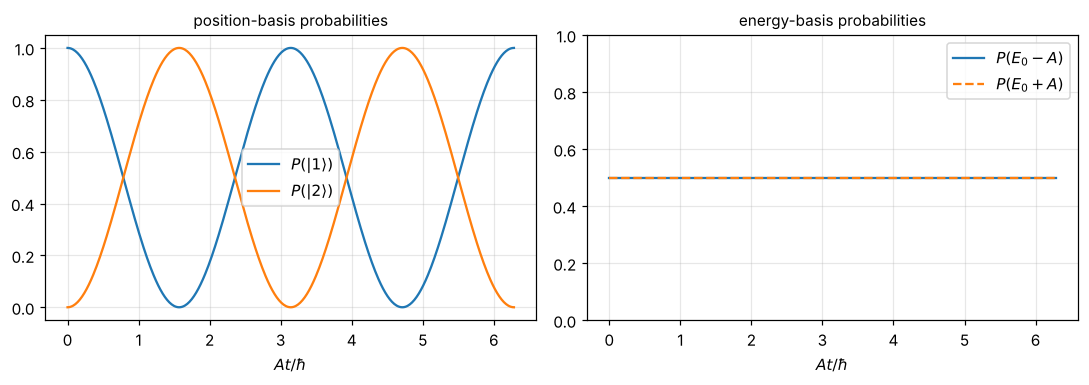

In [3]:
#| label: fig-two-level-measurement
#| caption: "The two-well system started in |1⟩ (A = 1, ħ = 1). Left, probabilities of finding it in well 1 or well 2 oscillate with period πħ/A. Right, the probabilities for an energy measurement stay at ½ each the whole time; energy is conserved, position is not."
tt = np.linspace(0, 2 * np.pi, 400)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(tt, np.cos(tt)**2, label="$P(|1\\rangle)$"); a1.plot(tt, np.sin(tt)**2, label="$P(|2\\rangle)$")
a1.set_xlabel("$At/\\hbar$"); a1.legend(); a1.set_title("position-basis probabilities", fontsize=10)
a2.plot(tt, 0.5 + 0 * tt, label="$P(E_0 - A)$"); a2.plot(tt, 0.5 + 0 * tt, "--", label="$P(E_0 + A)$")
a2.set_ylim(0, 1); a2.set_xlabel("$At/\\hbar$"); a2.legend(); a2.set_title("energy-basis probabilities", fontsize=10)
plt.tight_layout(); plt.show()

## Compatible and Incompatible Observables

If two Hermitian operators commute, $[\hat A, \hat B] = 0$, they share a complete set of eigenvectors, so a state can be determinate for both at once: the observables are **compatible**. Measuring $A$, then $B$, then $A$ again returns the first result.

If they do not commute, no such common basis exists in general. Measuring $B$ collapses the state into an eigenvector of $\hat B$, which is a superposition of $\hat A$'s eigenvectors, and the next $A$ measurement is uncertain again. The canonical example is $[\hat x, \hat p] = i\hbar$.

## The Generalized Uncertainty Principle

:::{prf:theorem} Robertson uncertainty relation
:label: thm-robertson

For any two observables and any state,

$$
\sigma_A^2\sigma_B^2\ge\left(\frac{1}{2i}\left\langle[\hat A, \hat B]\right\rangle\right)^2 .
$$ (eq-generalized-uncertainty)
:::

:::{prf:proof}
:class: dropdown

Let $|f\rangle = (\hat A - \langle A\rangle)|\Psi\rangle$ and $|g\rangle = (\hat B - \langle B\rangle)|\Psi\rangle$. Then $\sigma_A^2 = \langle f|f\rangle$ and $\sigma_B^2 = \langle g|g\rangle$ (Hermiticity moves the operator to the bra). By the Schwarz inequality (Q-M3),

$$
\sigma_A^2\sigma_B^2\ge|\langle f|g\rangle|^2\ge\left(\operatorname{Im}\langle f|g\rangle\right)^2 = \left(\frac{\langle f|g\rangle - \langle g|f\rangle}{2i}\right)^2 .
$$

Expanding, $\langle f|g\rangle - \langle g|f\rangle = \langle\hat A\hat B\rangle - \langle\hat B\hat A\rangle = \langle[\hat A, \hat B]\rangle$, the $\langle A\rangle\langle B\rangle$ terms cancelling.
:::

For $\hat x$ and $\hat p$, $\frac{1}{2i}\langle i\hbar\rangle = \hbar/2$: the Heisenberg relation $\sigma_x\sigma_p\ge\hbar/2$, now for every state. Equality needs $|g\rangle\propto i|f\rangle$ with a real proportionality constant, which forces a Gaussian.

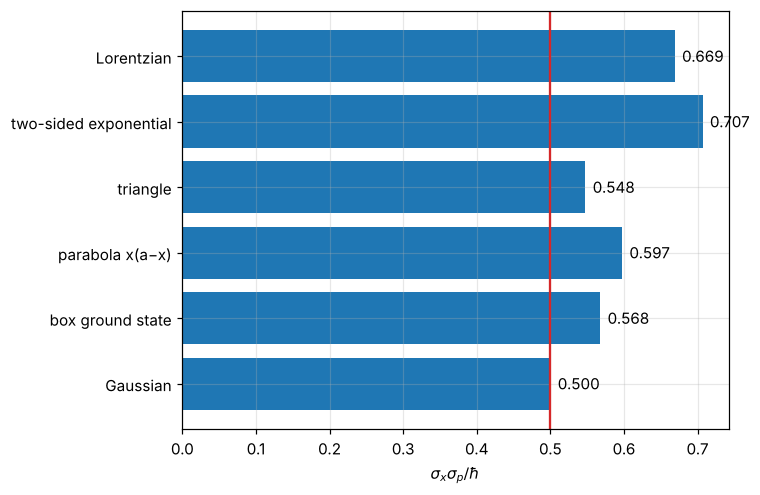

In [4]:
#| label: fig-uncertainty-products
#| caption: "σ_x σ_p (in units of ħ) for several normalized shapes, computed numerically. Only the Gaussian reaches the bound ½ (red line). Every other shape lands above it; the two-sided exponential (a cusp at the center) and the Lorentzian (long tails that inflate σ_x) are farthest away."
X = np.linspace(-12, 12, 24001); dx = X[1] - X[0]
shapes = {"Gaussian": np.exp(-X**2 / 2), "box ground state": np.where(abs(X) < 1, np.cos(np.pi * X / 2), 0),
          "parabola x(a−x)": np.where(abs(X) < 1, 1 - X**2, 0), "triangle": np.clip(1 - abs(X), 0, None),
          "two-sided exponential": np.exp(-abs(X)), "Lorentzian": 1 / (1 + X**2)}
names, prods = [], []
for name, f in shapes.items():
    f = f / np.sqrt(np.sum(f**2) * dx)
    sx = np.sqrt(np.sum(X**2 * f**2) * dx)
    sp_ = np.sqrt(np.sum(np.gradient(f, dx)**2) * dx)        # <p^2> = hbar^2 integral |psi'|^2
    names.append(name); prods.append(sx * sp_)
fig, ax = plt.subplots()
ax.barh(names, prods); ax.axvline(0.5, color="tab:red")
for i, v in enumerate(prods): ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlabel("$\\sigma_x\\sigma_p/\\hbar$"); plt.tight_layout(); plt.show()

::::{prf:example} Level 1 rung: how small can a hydrogen atom be?
:label: ex-hydrogen-size-estimate

Estimate the size and energy of hydrogen's ground state from the uncertainty principle alone.

:::{dropdown} Solution
Confine the electron within $r$, so $p\sim\hbar/r$. The energy is $E(r)\approx\hbar^2/2mr^2 - e^2/4\pi\epsilon_0r$. Minimizing, $r = 4\pi\epsilon_0\hbar^2/me^2 = a_0 = 0.0529$ nm and $E = -13.6$ eV. That this crude estimate hits the exact answer is partly luck, but it explains the physics: squeezing the electron closer raises its kinetic energy faster than it lowers its potential energy, so atoms do not collapse.
:::
::::

## Time Evolution of Expectation Values

Differentiate $\langle Q\rangle = \langle\Psi|\hat Q|\Psi\rangle$ using the Schrödinger equation:

$$
\frac{d\langle Q\rangle}{dt} = \frac i\hbar\left\langle[\hat H, \hat Q]\right\rangle + \left\langle\frac{\partial\hat Q}{\partial t}\right\rangle .
$$ (eq-heisenberg-eom)

An observable that commutes with $\hat H$ (and has no explicit time dependence) is **conserved**. Topic 1's Ehrenfest theorem is this equation for $\hat x$ and $\hat p$.

**Energy–time uncertainty.** Combining {eq}`eq-heisenberg-eom` with {eq}`eq-generalized-uncertainty` for $\hat H$ and $\hat Q$ gives $\sigma_H\,\Delta t\ge\hbar/2$, where $\Delta t = \sigma_Q/|d\langle Q\rangle/dt|$ is the time it takes $\langle Q\rangle$ to change by one standard deviation. Time is not an operator, so this is a different kind of statement: a state with sharp energy changes slowly. An unstable particle with lifetime $\tau$ has an energy spread $\sim\hbar/\tau$, which is why short-lived resonances appear as broad peaks.

In [5]:
# Commutators used constantly: [x, p^n] and [x, H] for H = p^2/2m + V(x)
x = sp.symbols("x", real=True); m = sp.symbols("m", positive=True)
f = sp.Function("f")(x); V = sp.Function("V")(x)
P = lambda g: -sp.I * hb * sp.diff(g, x)
Hop = lambda g: P(P(g)) / (2 * m) + V * g
display(Math(r"[\hat x, \hat p^2]f = " + sp.latex(sp.simplify(x * P(P(f)) - P(P(x * f))))))
display(Math(r"[\hat H, \hat x]f = " + sp.latex(sp.simplify(Hop(x * f) - x * Hop(f)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The second line says $[\hat H, \hat x] = -i\hbar\hat p/m$, so {eq}`eq-heisenberg-eom` gives $d\langle x\rangle/dt = \langle p\rangle/m$, the first Ehrenfest equation.

## Looking Ahead to Level 3

Everything so far assumed a definite state vector, a **pure state**. A beam from an oven, or one half of an entangled pair, is instead a statistical mixture: state $|\psi_i\rangle$ with probability $w_i$. Sakurai describes it by the **density operator** $\hat\rho = \sum_iw_i|\psi_i\rangle\langle\psi_i|$, with $\langle Q\rangle = \operatorname{Tr}(\hat\rho\hat Q)$. A mixture of spin up and spin down with equal weights, $\hat\rho = \tfrac12\mathsf 1$, gives the same results for every spin measurement as no preferred direction at all, and no pure state can do that.

## Exercises

### Exercises

1. For the two-level system, find $\langle H\rangle$ and $\sigma_H$ in the state $|1\rangle$. Check the energy–time relation using $Q = |1\rangle\langle1|$.
2. Find $\sigma_{S_x}\sigma_{S_y}$ and the Robertson bound for a spin-½ particle in the state $|{\uparrow}\rangle$ ($S_z = +\hbar/2$), using $\hat S = \tfrac\hbar2\vec\sigma$.
3. Show that $[\hat A\hat B, \hat C] = \hat A[\hat B, \hat C] + [\hat A, \hat C]\hat B$, and use it to find $[\hat x^2, \hat p]$.
4. Use {eq}`eq-heisenberg-eom` to show that $\langle p\rangle$ is constant for a free particle, and that $\langle x\rangle$ grows linearly.
5. A state of the infinite well is $\tfrac{1}{\sqrt2}(\psi_1 + \psi_2)$. What are the possible results of an energy measurement and their probabilities? What is the state just after measuring $E_2$?

:::{dropdown} Hints
1. $\langle1|\mathsf H|1\rangle = E_0$; $\langle1|\mathsf H^2|1\rangle = E_0^2 + A^2$.
2. In $|{\uparrow}\rangle$, $\langle S_x\rangle = \langle S_y\rangle = 0$ and $\langle S_x^2\rangle = \hbar^2/4$; $[S_x, S_y] = i\hbar S_z$.
3. Expand both sides; then $[\hat x^2, \hat p] = \hat x[\hat x, \hat p] + [\hat x, \hat p]\hat x$.
4. $[\hat H, \hat p] = 0$ when $V = 0$.
5. Postulates 3 and 4.
:::

:::{dropdown} Answers
1. $\sigma_H = A$. $\langle Q\rangle = \cos^2(At/\hbar)$ changes on the timescale $\hbar/A$, so $\sigma_H\Delta t\sim\hbar$, consistent with $\ge\hbar/2$.
2. $\sigma_{S_x}\sigma_{S_y} = \hbar^2/4$; bound $= |\tfrac{1}{2i}i\hbar\langle S_z\rangle| = \hbar^2/4$. Equality.
3. $[\hat x^2, \hat p] = 2i\hbar\hat x$.
4. $d\langle p\rangle/dt = 0$; $d\langle x\rangle/dt = \langle p\rangle/m$, constant, so $\langle x\rangle$ is linear in $t$.
5. $E_1$ or $E_2$, each with probability ½. After finding $E_2$, the state is $\psi_2$ (times a phase).
:::

## Summary

- States are vectors, observables Hermitian operators; outcomes are eigenvalues with probabilities $|\langle q_n|\Psi\rangle|^2$, followed by collapse.
- Two-level systems show the whole formalism in $2\times2$ matrices: energy eigenstates are stationary, other states oscillate.
- Commuting observables can be sharp together; non-commuting ones obey $\sigma_A\sigma_B\ge|\langle[\hat A,\hat B]\rangle|/2$.
- $d\langle Q\rangle/dt = \tfrac i\hbar\langle[\hat H, \hat Q]\rangle$: operators commuting with $\hat H$ are conserved; energy–time uncertainty links $\sigma_H$ to how fast things change.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.